## 1. Evaluation setup

- Prediction time: before scheduled departure, so only schedule and route facts are predictors
- Split by date, never random:
  1. Train: Jan 1-21
  2. Test: Jan 22-31 (scored once)
  3. For tuning, train is split again into fit (Jan 1-14) and validation (Jan 15-21)
- Leakage checks:
  1. ARR_DEL15, CANCELLED and DIVERTED are never predictors
  2. FL_DATE is only used to split
  3. Encoders and scalers are fit on training data only

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)


In [2]:
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)

In [3]:
df = pd.read_csv("T_ONTIME_REPORTING.csv")
df["FL_DATE"] = pd.to_datetime(df["FL_DATE"])
clean = df[(df["CANCELLED"] == 0) & (df["DIVERTED"] == 0)].copy()   # drop flights with no outcome
clean = clean.drop_duplicates()
clean["DEP_HOUR"] = (clean["CRS_DEP_TIME"] // 100) % 24
print("Clean flights:", len(clean), " Missing values:", int(clean.isna().sum().sum()))

# Split by date: train Jan 1-21, test Jan 22-31
train_full = clean[clean["FL_DATE"] < "2025-01-22"]
test       = clean[clean["FL_DATE"] >= "2025-01-22"]

# Hyperparam tuning split inside train: fit Jan 1-14, validation Jan 15-21
fit = train_full[train_full["FL_DATE"] < "2025-01-15"]
val = train_full[train_full["FL_DATE"] >= "2025-01-15"]

# Checks: no test dates in train, no validation dates in fit
assert train_full["FL_DATE"].max() < test["FL_DATE"].min()
assert fit["FL_DATE"].max() < val["FL_DATE"].min()
FORBIDDEN = {"ARR_DEL15", "CANCELLED", "DIVERTED", "FL_DATE"}

for name, d in [("Fit", fit), ("Validation", val), ("Train", train_full), ("Test", test)]:
    print(f"{name:10} {d['FL_DATE'].min().date()} to {d['FL_DATE'].max().date()}  "
          f"rows = {len(d):,}  delay rate = {d['ARR_DEL15'].mean():.3f}")

Clean flights: 522269  Missing values: 0
Fit        2025-01-01 to 2025-01-14  rows = 237,115  delay rate = 0.233
Validation 2025-01-15 to 2025-01-21  rows = 116,049  delay rate = 0.172
Train      2025-01-01 to 2025-01-21  rows = 353,164  delay rate = 0.213
Test       2025-01-22 to 2025-01-31  rows = 169,105  delay rate = 0.135


## 2. Baselines

1. Benchmark: always predict on time
2. Simple baseline: PyTorch logistic regression on DEP_HOUR, DAY_OF_WEEK and DISTANCE (the patterns from the Checkpoint 1 EDA)
3. Full model: the same PyTorch logistic regression on all predictors

## 3. Preprocessing (fit on training data only)

- Numeric (DISTANCE, CRS_ELAPSED_TIME): standardized
- Categorical (DEP_HOUR, DAY_OF_WEEK, OP_UNIQUE_CARRIER, ORIGIN, DEST): one-hot encoded
  - DEP_HOUR is categorical because the delay pattern in Figure 2 is not linear
  - Categories with fewer than 100 training flights are grouped as infrequent, and unseen categories are handled the same way
- MONTH is dropped (constant in January)

In [4]:
# Predictors for full model
FULL_CAT = ["DEP_HOUR", "DAY_OF_WEEK", "OP_UNIQUE_CARRIER", "ORIGIN", "DEST"]
FULL_NUM = ["CRS_ELAPSED_TIME", "DISTANCE"]

# Predictors for simple baseline model
SIMPLE_CAT = ["DEP_HOUR", "DAY_OF_WEEK"]
SIMPLE_NUM = ["DISTANCE"]

def make_pre(cat, num):
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), cat),
    ])

def transform(pre, d):
    return sparse.csr_matrix(pre.transform(d))

## 4. Model: logistic regression in PyTorch

- One linear layer (nn.Linear) that outputs a logit
- Loss: BCEWithLogitsLoss (binary cross-entropy)
- Optimizer: Adam
- Class weight: on-time count divided by late count in the training data, so missing a late flight costs more
- Data loading: a Dataset class (FlightData) wraps the sparse features, and a DataLoader with a BatchSampler feeds batches of 4,096 rows

In [3]:
from torch.utils.data import Dataset, DataLoader, RandomSampler, SequentialSampler, BatchSampler

class FlightData(Dataset):
    """Wraps a sparse feature matrix and labels. Given row numbers, returns that batch as dense tensors."""
    def __init__(self, X, y=None):
        self.X = X
        self.y = None if y is None else torch.from_numpy(np.asarray(y, dtype=np.float32))

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):                 # idx is a list of row numbers (from BatchSampler)
        x = torch.from_numpy(self.X[idx].toarray().astype(np.float32))
        return x if self.y is None else (x, self.y[idx])

BATCH = 4096
def make_loader(X, y=None, shuffle=False, seed=SEED):
    ds = FlightData(X, y)
    base = RandomSampler(ds, generator=torch.Generator().manual_seed(seed)) if shuffle else SequentialSampler(ds)
    return DataLoader(ds, sampler=BatchSampler(base, BATCH, drop_last=False), batch_size=None)

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return torch.cat([torch.sigmoid(model(xb).squeeze(1)) for xb in make_loader(X)]).numpy()

def train_lr(Xtr, ytr, lr, wd, epochs, pos_weight, seed=SEED, Xva=None, yva=None):
    torch.manual_seed(seed)
    loader = make_loader(Xtr, ytr, shuffle=True, seed=seed)
    model = nn.Linear(Xtr.shape[1], 1)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float(pos_weight)))
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    hist = []
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss = loss_fn(model(xb).squeeze(1), yb)
            loss.backward(); opt.step()
        if Xva is not None:
            hist.append(roc_auc_score(yva, predict(model, Xva)))
    return model, hist

## 5. Hyperparameters (tuned on validation only)

- Tuned: learning rate and L2 strength (weight decay)
- Number of epochs: the best validation epoch
- The test set is not used here

In [4]:
pre_fit = make_pre(FULL_CAT, FULL_NUM).fit(fit)
Xf, Xv = transform(pre_fit, fit), transform(pre_fit, val)
yf, yv = fit["ARR_DEL15"].values.astype(np.float32), val["ARR_DEL15"].values.astype(np.float32)
pw_fit = (1 - yf.mean()) / yf.mean()
print("Features:", Xf.shape[1], " pos_weight:", round(pw_fit, 2))

rows, MAX_EP = [], 8
for lr in [1e-3, 1e-2]:
    for wd in [0, 1e-5, 1e-4]:
        _, hist = train_lr(Xf, yf, lr, wd, MAX_EP, pw_fit, Xva=Xv, yva=yv)
        rows.append({"lr": lr, "weight_decay": wd, "best_epoch": int(np.argmax(hist)) + 1,
                     "val_AUC": max(hist)})
grid = pd.DataFrame(rows).sort_values("val_AUC", ascending=False).round(4)
display(grid)
best = grid.iloc[0]
BEST = dict(lr=float(best.lr), wd=float(best.weight_decay), epochs=int(best.best_epoch))
print("Chosen:", BEST)

Features: 391  pos_weight: 3.29


,lr,weight_decay,best_epoch,val_AUC
5,0.010,0.0001,5,0.6268
4,0.010,0.0000,5,0.6267
3,0.010,0.0000,5,0.6266
0,0.001,0.0000,7,0.6235
1,0.001,0.0000,7,0.6235
2,0.001,0.0001,7,0.6235


Chosen: {'lr': 0.01, 'wd': 0.0001, 'epochs': 5}


In [5]:
def best_threshold(y, p):
    ts = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(y, p >= t) for t in ts]
    return float(ts[int(np.argmax(f1s))])

def run_model(cat, num, seed=SEED):
    """Tune the decision threshold on validation, then refit on all training data and score test."""
    pre_a = make_pre(cat, num).fit(fit)
    m_a, _ = train_lr(transform(pre_a, fit), yf, BEST["lr"], BEST["wd"], BEST["epochs"], pw_fit, seed)
    thr = best_threshold(yv, predict(m_a, transform(pre_a, val)))
    pre = make_pre(cat, num).fit(train_full)                       # training data only
    Xt = transform(pre, train_full); yt = train_full["ARR_DEL15"].values.astype(np.float32)
    model, _ = train_lr(Xt, yt, BEST["lr"], BEST["wd"], BEST["epochs"], (1 - yt.mean()) / yt.mean(), seed)
    return model, pre, thr, predict(model, transform(pre, test))

y_test = test["ARR_DEL15"].values
simple_model, simple_pre, thr_s, p_simple = run_model(SIMPLE_CAT, SIMPLE_NUM)
full_model, full_pre, thr_f, p_full = run_model(FULL_CAT, FULL_NUM)
print("Chosen thresholds (validation F1): simple", thr_s, " full", thr_f)

Chosen thresholds (validation F1): simple 0.43999999999999995  full 0.4699999999999999


## 6. Results (test set, Jan 22-31)

In [6]:
def metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0), "F1": f1_score(y, pred, zero_division=0),
            "ROC AUC": roc_auc_score(y, p), "PR AUC": average_precision_score(y, p)}

p_bench = np.zeros(len(test))
results = pd.DataFrame({
    "Benchmark (always on-time)": metrics(y_test, p_bench, 0.5),
    "Simple baseline (hour, day, distance)": metrics(y_test, p_simple, thr_s),
    "Full model (all predictors)": metrics(y_test, p_full, thr_f),
}).T.round(3)
display(results)
print("Test delay rate (PR AUC of a no-skill model):", round(y_test.mean(), 3))

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Benchmark (always on-time),0.865,0.000,0.000,0.000,0.500,0.135
"Simple baseline (hour, day, distance)",0.411,0.135,0.623,0.222,0.501,0.134
Full model (all predictors),0.523,0.151,0.549,0.237,0.547,0.154


Test delay rate (PR AUC of a no-skill model): 0.135


In [7]:
# Stability: retrain the full model with 3 different seeds
aucs = []
for s in [0, 1, 2]:
    _, _, _, p = run_model(FULL_CAT, FULL_NUM, seed=s)
    aucs.append(roc_auc_score(y_test, p))
print("Full-model test ROC AUC across seeds:", np.round(aucs, 4), " mean", round(np.mean(aucs), 4), " std", round(np.std(aucs), 4))

Full-model test ROC AUC across seeds: [0.5475 0.5487 0.5491]  mean 0.5484  std 0.0007


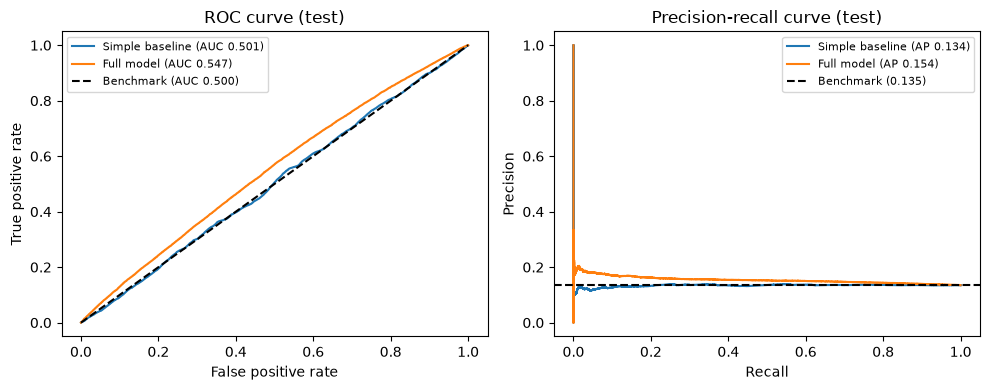

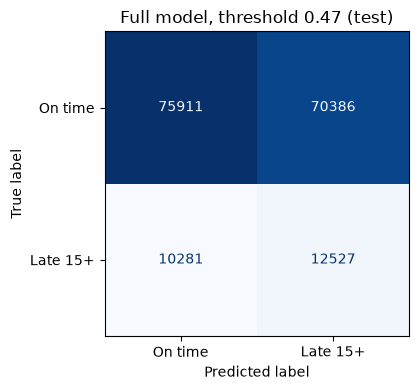

In [8]:
# Figure 4: ROC and precision-recall curves
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for name, p in [("Simple baseline", p_simple), ("Full model", p_full)]:
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); ax[1].plot(rc, pr, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", label="Benchmark (AUC 0.500)")
ax[1].axhline(y_test.mean(), color="k", ls="--", label=f"Benchmark ({y_test.mean():.3f})")
ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (test)")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (test)")
for a in ax: a.legend(loc="best", fontsize=8)
plt.tight_layout(); plt.savefig("fig4_roc_pr.png", dpi=300, bbox_inches="tight"); plt.show()

# Figure 5: confusion matrix for the full model
fig, ax = plt.subplots(figsize=(4.5, 4))
cm = confusion_matrix(y_test, (p_full >= thr_f).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["On time", "Late 15+"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title(f"Full model, threshold {thr_f:.2f} (test)")
plt.tight_layout(); plt.savefig("fig5_confusion.png", dpi=300, bbox_inches="tight"); plt.show()

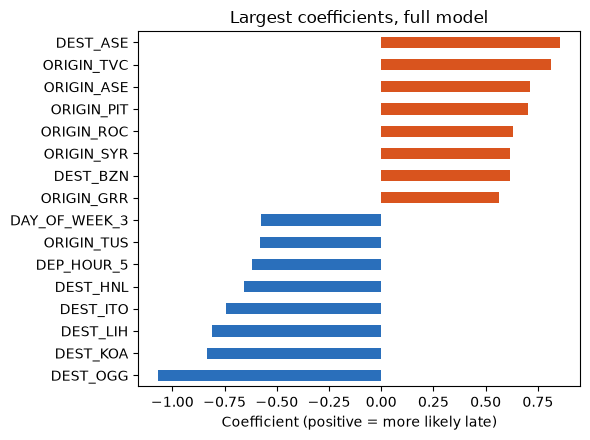

In [9]:
# Figure 6: largest coefficients of the full model (what drives predictions)
names = full_pre.get_feature_names_out()
w = pd.Series(full_model.weight.detach().numpy().ravel(), index=names)
w.index = [n.replace("cat__", "").replace("num__", "") for n in w.index]
top = pd.concat([w.sort_values().head(8), w.sort_values().tail(8)])
fig, ax = plt.subplots(figsize=(6, 4.5))
top.plot(kind="barh", color=["#2a6fbb" if v < 0 else "#d9541e" for v in top], ax=ax)
ax.set(xlabel="Coefficient (positive = more likely late)", title="Largest coefficients, full model")
plt.tight_layout(); plt.savefig("fig6_coef.png", dpi=300, bbox_inches="tight"); plt.show()

## 7. Cases of interest

In [10]:
cases = test.copy()
cases["P(late)"] = p_full.round(3); cases["Actual"] = np.where(y_test == 1, "late", "on time")
cols = ["FL_DATE", "OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "DEP_HOUR", "DISTANCE", "P(late)", "Actual"]
print("Correct, most confident late flight:");   display(cases[cases.Actual == "late"].nlargest(1, "P(late)")[cols])
print("Wrong, most confident false alarm (predicted late, arrived on time):"); display(cases[cases.Actual == "on time"].nlargest(1, "P(late)")[cols])
print("Wrong, most confident miss (late flight given the lowest probability):"); display(cases[cases.Actual == "late"].nsmallest(1, "P(late)")[cols])

Correct, most confident late flight:


,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,DEP_HOUR,DISTANCE,P(late),Actual
58650,2025-01-25,OO,DEN,ASE,20,125.0,0.875,late


Wrong, most confident false alarm (predicted late, arrived on time):


,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,DEP_HOUR,DISTANCE,P(late),Actual
94121,2025-01-27,OO,DEN,ASE,20,125.0,0.895,on time


Wrong, most confident miss (late flight given the lowest probability):


,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,DEP_HOUR,DISTANCE,P(late),Actual
10870,2025-01-22,UA,SFO,LIH,8,2447.0,0.083,late
